# 1 次のローパスフィルタ(LPF)

**低い周波数を通し、高い周波数を通しにくくする**回路です。雑音を減らす、信号をなめらかにする、などに使います。

この回では、Mimic を 1 次の LPF にして、正弦波と方形波を入れます。出力の振幅が小さくなる様子、遅れる様子、方形波の角がなまる様子を見ます。

> 準備:[講義の README](../README.md) の結線をして、測定器のスケッチ(MimicLab)を UNO R4 に書き込んでおきます。

## 回路

![1 次の LPF の回路](01_lpf/circuit.svg)

抵抗 R とコンデンサ C の **RC 回路**の後ろに、オペアンプの**ボルテージフォロワ**(ゲイン 1)を置いた回路です。フォロワは、後ろにつなぐ回路が C の電圧を引っ張って特性が変わらないようにする「緩衝(バッファ)」の役目をします。

5 V だけで動く(単電源の)回路では、C の下側を 0 V ではなく 2.5 V(**信号のグランド**)につなぎます。Mimic では、この電圧を **Vref** と呼びます(既定で 2.5 V)。

Mimic は回路をそのまま持っているのではなく、この回路と同じ入出力の関係(下の伝達関数)をデジタルの計算でまねています。

## 原理

C のインピーダンス(交流に対する抵抗)は $Z_C = \dfrac{1}{j 2\pi f C}$ で、**周波数が高いほど小さく**なります。R と C で入力を分圧しているので、

- 低い周波数:C はほとんど電流を流さない(開放に近い)→ 入力がそのまま出る
- 高い周波数:C が電流をよく流す(短絡に近い)→ 出力が小さくなる

入力に対する出力の比(**伝達関数**)は次のようになります(導出は省きます)。

$$H(f) = \frac{1}{1 + j\,f/f_c}, \qquad f_c = \frac{1}{2\pi R C}$$

$f_c$ を**カットオフ周波数**といいます。振幅は $|H| = 1/\sqrt{1 + (f/f_c)^2}$、位相は $-\arctan(f/f_c)$ です。

| 周波数 | 振幅 | 位相 |
|---|---|---|
| $f \ll f_c$ | 1(そのまま) | 0° |
| $f = f_c$ | $1/\sqrt{2} \approx 0.707$(−3 dB) | −45° |
| $f \gg f_c$ | $f_c / f$(周波数が 10 倍で 1/10、−20 dB/dec) | −90° に近づく |

![1 次の LPF の周波数特性(模式図)](01_lpf/response.svg)

**時間で見ると**:入力が急に変わったとき、出力は $1 - e^{-t/\tau}$ の形で追いかけます。$\tau = RC = \dfrac{1}{2\pi f_c}$ を**時定数**といい、$\tau$ の時間で変化の 63 % まで、$5\tau$ でほぼ 100 % まで進みます。

## Mimic の設定と回路定数

| Mimic(Python) | ライブラリ(Arduino) | 回路 |
|---|---|---|
| `lab.mimic.filter1st_lpf(fc)` | `mimic.setFilter1stLPF(fc)` | $f_c = \dfrac{1}{2\pi R C}$ |

Mimic では R と C ではなく、**カットオフ周波数 $f_c$ を直接**設定します。同じ $f_c$ になる R と C の組み合わせはいくらでもあり、特性はどれも同じです。

例:$f_c$ = 100 Hz は、R = 16 kΩ、C = 0.1 µF($f_c \approx$ 99.5 Hz)の回路にあたります。時定数は $\tau \approx$ 1.59 ms です。

## 準備:測定器につなぐ

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from mimiclab import MimicLab

lab = MimicLab()  # finds the Arduino; or MimicLab("COM5")
lab

MimicLab(port='COM4', ver=0.1.0, mimic=20261123)

`mimic=` のあとに Mimic のファームのビルド日が出ていれば、Mimic ともつながっています(`none` なら結線を確かめて `lab.mimic.begin()`)。

Mimic を $f_c$ = 100 Hz の LPF にします。

In [2]:
FC = 100  # cutoff frequency [Hz]
lab.mimic.filter1st_lpf(FC)

## 実験 1:正弦波を $f_c$ で入れる

信号発生器から 100 Hz($= f_c$)、振幅(ピーク)1 V の正弦波を出します。波形の中心の電圧は**オフセット**(offset)と呼び、ここでは 2.5 V です(市販の信号発生器のつまみと同じ名前です)。Mimic は 2.5 V を信号の基準(Vref)として受け取り、入力の Vref からのずれを信号として処理します。

表のとおりなら、出力の振幅は 0.707 倍、位相は 45° 遅れるはずです。

In [3]:
lab.fg.sine(FC, 1.0)  # 100 Hz, 1 V peak, around 2.5 V

{'wave': 'sine', 'freq': 100.0, 'amp': 1.0, 'offset': 2.5}

20 kHz で 2000 点(0.1 秒、100 Hz なら 10 周期)取り込みます。取り込みは信号発生器の位相 0 から始まるので、何度取り込んでも同じところから始まります。

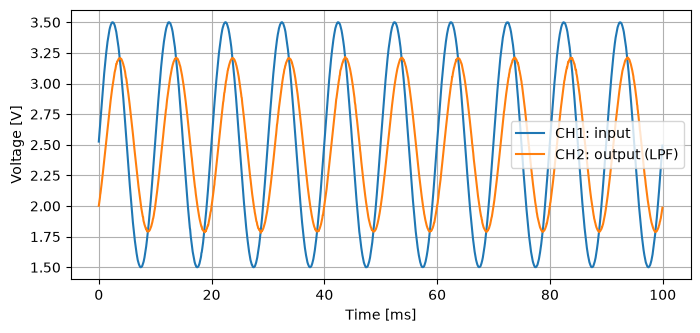

In [4]:
t, ch1, ch2 = lab.scope.capture(2000)  # 2000 points at 20 kHz

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(t * 1e3, ch1, label="CH1: input")
ax.plot(t * 1e3, ch2, label="CH2: output (LPF)")
ax.set_xlabel("Time [ms]")
ax.set_ylabel("Voltage [V]")
ax.grid(True)
ax.legend()
plt.show()

周波数がわかっている正弦波なので、$a \sin(2\pi f t) + b \cos(2\pi f t) + c$ を最小二乗法で当てはめて、振幅と位相を求めます。

In [5]:
def fit_sine(t, v, freq):
    """Amplitude [V], phase [deg] and offset [V] of a sine of a known frequency."""
    w = 2 * np.pi * freq
    A = np.column_stack([np.sin(w * t), np.cos(w * t), np.ones_like(t)])
    a, b, c = np.linalg.lstsq(A, v, rcond=None)[0]
    return np.hypot(a, b), np.degrees(np.arctan2(b, a)), c

amp_in, ph_in, dc_in = fit_sine(t, ch1, FC)
amp_out, ph_out, dc_out = fit_sine(t, ch2, FC)
print(f"input : {amp_in:.3f} V, offset {dc_in:.3f} V")
print(f"output: {amp_out:.3f} V, offset {dc_out:.3f} V")
print(f"gain  : {amp_out / amp_in:.3f}   (theory 0.707)")
print(f"phase : {ph_out - ph_in:.1f} deg (theory -45)")

input : 1.000 V, offset 2.500 V
output: 0.707 V, offset 2.499 V
gain  : 0.707   (theory 0.707)
phase : -46.2 deg (theory -45)


振幅の比はほぼ理論どおりになります。位相は理論より 1° ほど多く遅れます。Mimic はデジタルで計算するので、入力から出力までに数十 µs の遅れがあるためです(100 Hz では 10 µs が 0.36°)。また、この測定器は CH1 と CH2 を数 µs ずらして読んでいます。

## 実験 2:方形波を入れる(なまり)

20 Hz の方形波を入れます。半周期は 25 ms で、時定数(1.59 ms)よりずっと長いので、出力は毎回ほぼ入力の値まで追いつきます。

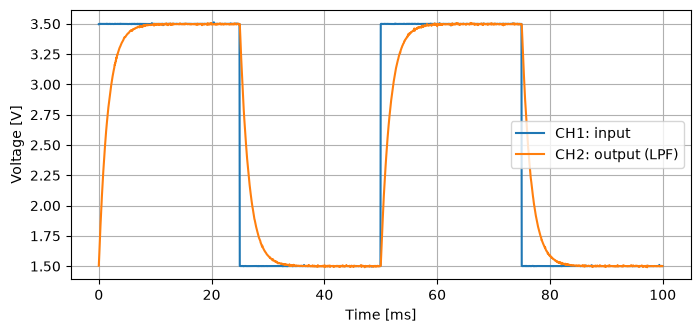

In [6]:
lab.fg.square(20, 1.0)  # 20 Hz, 1 V peak
t, ch1, ch2 = lab.scope.capture(2000)  # 0.1 s: two periods

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(t * 1e3, ch1, label="CH1: input")
ax.plot(t * 1e3, ch2, label="CH2: output (LPF)")
ax.set_xlabel("Time [ms]")
ax.set_ylabel("Voltage [V]")
ax.grid(True)
ax.legend()
plt.show()

角がなまって、なだらかな曲線になりました。立ち上がりを拡大して、出力が変化の 63 % に届くまでの時間(時定数)を読みます。取り込みは 20 kHz なので、時間の目盛りは 50 µs きざみです。

time constant: 1.62 ms (theory 1.59 ms)


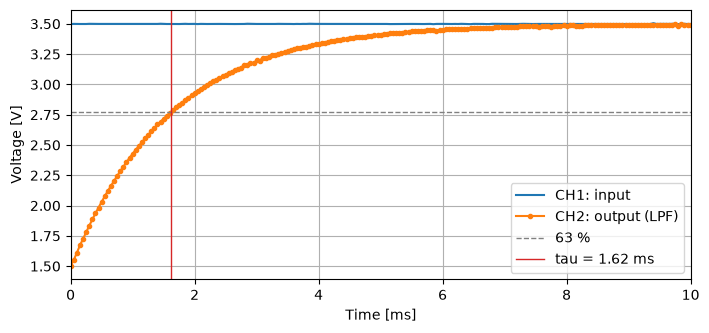

In [7]:
lo, hi = ch1.min(), ch1.max()
t_edge = t[np.argmax(ch1 > (lo + hi) / 2)]  # rising edge of the input
level = lo + 0.632 * (hi - lo)              # 63 % of the step
i = max(int(np.argmax(ch2 > level)), 1)     # first point of the output above it
t63 = np.interp(level, ch2[i - 1:i + 1], t[i - 1:i + 1])
tau = t63 - t_edge
print(f"time constant: {tau * 1e3:.2f} ms (theory {1e3 / (2 * np.pi * FC):.2f} ms)")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(t * 1e3, ch1, label="CH1: input")
ax.plot(t * 1e3, ch2, ".-", label="CH2: output (LPF)")
ax.axhline(level, color="gray", ls="--", lw=1, label="63 %")
ax.axvline(t63 * 1e3, color="C3", lw=1, label=f"tau = {tau * 1e3:.2f} ms")
ax.set_xlim(0, 10)
ax.set_xlabel("Time [ms]")
ax.set_ylabel("Voltage [V]")
ax.grid(True)
ax.legend()
plt.show()

## 実験 3:$f_c$ を変える

$f_c$ を変えて、同じ方形波を入れます。$f_c$ が低いほど時定数が長く、出力はゆっくり追いかけます。$f_c$ = 30 Hz では時定数が 5.3 ms で、半周期(25 ms)のあいだに追いつききれません。

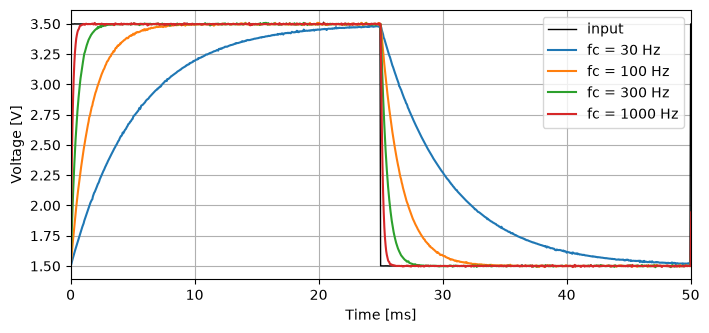

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(t * 1e3, ch1, "k", lw=1, label="input")
for fc in [30, 100, 300, 1000]:
    lab.mimic.filter1st_lpf(fc)
    t, ch1, ch2 = lab.scope.capture(2000)
    ax.plot(t * 1e3, ch2, label=f"fc = {fc} Hz")
ax.set_xlim(0, 50)
ax.set_xlabel("Time [ms]")
ax.set_ylabel("Voltage [V]")
ax.grid(True)
ax.legend()
plt.show()

## やってみよう

下のセルの値(大文字の名前)を**1 つずつ**変えて実行し、オシロの波形と数値がどう変わるかを自分の目で確かめましょう。どの値を順に試すとよいかと、何が見えるはずかは「ヒント」に書いてあります。

> Run All で最後まで実行したあと(接続を閉じたあと)にやるときは、最初の「測定器につなぐ」のセルをもう一度実行してから始めます。

### 1. 方形波で $f_c$ を変える

方形波を入れたまま $f_c$ を変えて、出力の形を見ます。
<details><summary>ヒント</summary>

`FC_TRY` を 50 → 200 → 2000 と変えてみましょう。$f_c$ が低い(時定数が長い)ほど角が大きくなまり、ゆっくり追いかけます。$f_c$ が高いと、ほとんど入力の形のままです。

</details>

time constant: 3.18 ms


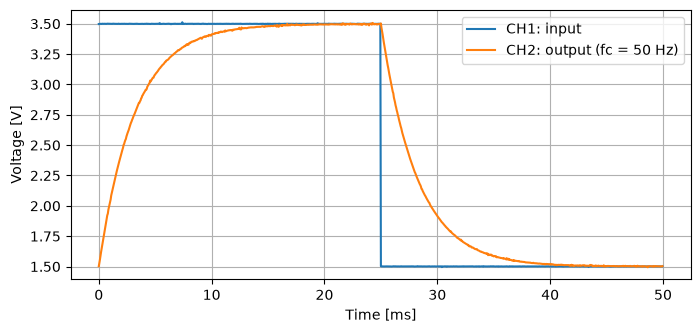

In [9]:
FC_TRY = 50   # cutoff frequency [Hz]

lab.mimic.filter1st_lpf(FC_TRY)
lab.fg.square(20, 1.0)
t, ch1, ch2 = lab.scope.capture(1000)
print(f"time constant: {1e3 / (2 * np.pi * FC_TRY):.2f} ms")
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(t * 1e3, ch1, label="CH1: input")
ax.plot(t * 1e3, ch2, label=f"CH2: output (fc = {FC_TRY} Hz)")
ax.set_xlabel("Time [ms]")
ax.set_ylabel("Voltage [V]")
ax.grid(True)
ax.legend()
plt.show()

### 2. 正弦波で $f_c$ を変える

今度は 100 Hz の正弦波を入れて、同じように $f_c$ を変えます。方形波のときと比べて、見た目はどう違うでしょうか。振幅と位相も数値で見ます。
<details><summary>ヒント</summary>

`FC_TRY` を 1 と同じく 50 → 200 → 2000 と変えてみましょう。

正弦波は、LPF を通っても**同じ周波数の正弦波のまま**で、変わるのは振幅と位相(遅れ)だけです。そのため $f_c$ を変えても形は変わらず、大きさと位置が少し変わるだけに見えます。数値では、ゲインは $1/\sqrt{1+(100/f_c)^2}$、位相は $-\arctan(100/f_c)$ のとおりに変わっています。

方形波は、いろいろな周波数の正弦波の重ね合わせです。周波数ごとに振幅と位相の変わり方が違うので、通ったあとの形が変わります(3 章のバンドパスフィルタの回でくわしく見ます)。

</details>

gain 0.448 (theory 0.447), phase -65.0 deg (theory -63.4)


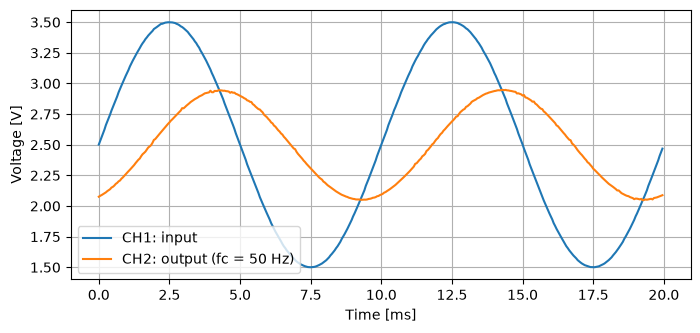

In [10]:
FC_TRY = 50   # cutoff frequency [Hz]

lab.mimic.filter1st_lpf(FC_TRY)
lab.fg.sine(100, 1.0)
t, ch1, ch2 = lab.scope.capture(400)
a1, p1, _ = fit_sine(t, ch1, 100)
a2, p2, _ = fit_sine(t, ch2, 100)
print(f"gain {a2 / a1:.3f} (theory {1 / np.sqrt(1 + (100 / FC_TRY) ** 2):.3f}), "
      f"phase {p2 - p1:.1f} deg (theory {-np.degrees(np.arctan(100 / FC_TRY)):.1f})")
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(t * 1e3, ch1, label="CH1: input")
ax.plot(t * 1e3, ch2, label=f"CH2: output (fc = {FC_TRY} Hz)")
ax.set_xlabel("Time [ms]")
ax.set_ylabel("Voltage [V]")
ax.grid(True)
ax.legend()
plt.show()

### 3. $f_c$ を信号よりずっと低くする

100 Hz の方形波を、$f_c$ の低い LPF に入れます。出力はどんな形になるでしょうか。
<details><summary>ヒント</summary>

`FC_LOW` を 50 → 20 → 5 と下げてみましょう。$f_c$ が信号の周波数よりずっと低くなると、出力は**三角波**に近い形になり、振幅はとても小さくなります。$f_c$ よりずっと高い周波数では、LPF は入力を時間で積み上げる**積分器**のように働くからです(4 章の積分器の回につながります)。

$f_c$ が低いほど落ち着くのに時間がかかるので、セルの中で少し待っています。

</details>

output: 1.842 - 3.155 V


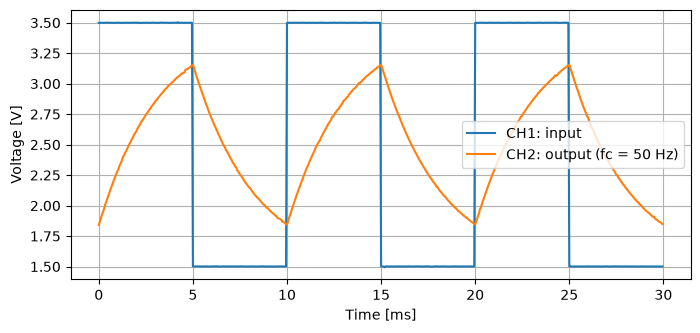

In [11]:
FC_LOW = 50   # [Hz]

import time
lab.mimic.filter1st_lpf(FC_LOW)
lab.fg.square(100, 1.0)
time.sleep(1.0)  # a slow filter needs time to settle
t, ch1, ch2 = lab.scope.capture(600)
print(f"output: {ch2.min():.3f} - {ch2.max():.3f} V")
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(t * 1e3, ch1, label="CH1: input")
ax.plot(t * 1e3, ch2, label=f"CH2: output (fc = {FC_LOW} Hz)")
ax.set_xlabel("Time [ms]")
ax.set_ylabel("Voltage [V]")
ax.grid(True)
ax.legend()
plt.show()

## まとめ

- 1 次の LPF は、$f_c = 1/(2\pi RC)$ より高い周波数を通しにくくする。$f_c$ では振幅 0.707 倍、位相 −45°。
- 時間で見ると、急な変化を時定数 $\tau = RC$ でなめらかにする(方形波の角がなまる)。
- Mimic では $f_c$ を直接設定する(`filter1st_lpf(fc)`)。

最後に Mimic を素通し(バイパス)に戻して、接続を閉じます。

In [12]:
lab.mimic.bypass()
lab.close()